In [47]:
import numpy as np
import matplotlib.pyplot as plt
import smplotlib
from astropy import constants as const, units as u
from scipy.optimize import curve_fit

def area_annulus(r_in,r_out):
    
    a_out = np.pi*r_out**2
    a_in = np.pi*r_in**2
    
    return a_out-a_in


### Part e) Calculating the surface density for each feeding area

In [48]:
# Make a dictionary of value, 'Planet':[orig_mass,inner_au,center_au,outer_au]
planet_dict = {'Mercury':[7.62e25,0.2,0.4,0.55],
               'Venus':[1.27e27,0.55,0.7,0.85],
               'Earth':[1.52e27,0.85,1,1.25],
               'Mars':[1.52e26,1.25,1.5,2.25],
               'Jupiter':[2.54e28,4,5,7.5],
               'Saturn':[2.54e28,7.5,10,15],
               'Uranus':[1.52e27,15,20,25],
               'Neptune':[1.52e27,25,30,35],
               'Asteroid Belt':[5.08e23,2.25,3,4]}

for key in planet_dict.keys():
    
    mass = planet_dict[key][0]*u.kg
    r_in = planet_dict[key][1]*u.au
    r_out = planet_dict[key][3]*u.au
    
    surface_area = area_annulus(r_in.to(u.meter).value,r_out.to(u.meter).value)*u.meter**2
    
    density = mass/surface_area
    
    planet_dict[key].append(density.value)
    
    print(f"{key}: {density:0.2}")

Mercury: 4.1e+03 kg / m2
Venus: 4.3e+04 kg / m2
Earth: 2.6e+04 kg / m2
Mars: 6.2e+02 kg / m2
Jupiter: 9e+03 kg / m2
Saturn: 2.1e+03 kg / m2
Uranus: 5.4e+01 kg / m2
Neptune: 3.6e+01 kg / m2
Asteroid Belt: 0.66 kg / m2


### Part f) Make a log-log plot of surface density vs orbital radius

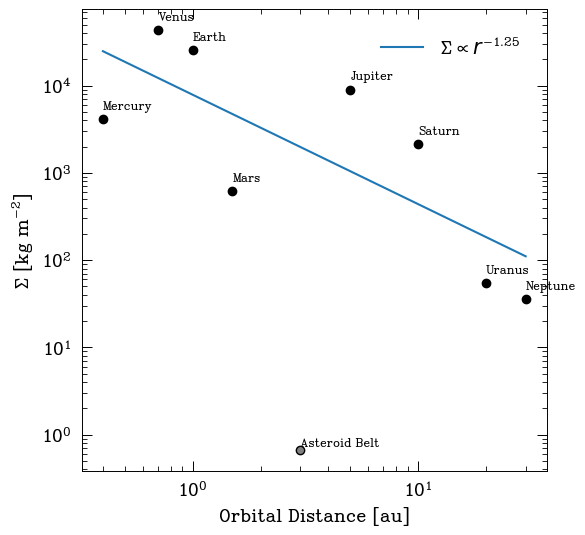

In [49]:
fig, ax = plt.subplots(figsize=(6,6))

fit_points = np.zeros((8,2))

for i,key in enumerate(planet_dict.keys()):
    
    if key=='Asteroid Belt':
        ax.scatter(planet_dict[key][2],planet_dict[key][4],c='grey')
        ax.text(s=key,x=planet_dict[key][2],y=1.1*planet_dict[key][4],fontsize=10)
        
    else:
        ax.scatter(planet_dict[key][2],planet_dict[key][4],c='k')
        ax.text(s=key,x=planet_dict[key][2],y=1.3*planet_dict[key][4],fontsize=10)
        fit_points[i,0] = planet_dict[key][2]
        fit_points[i,1] = planet_dict[key][4]
        
        
# Do a linear fit and plot

m, b = np.polyfit(np.log10(fit_points[:,0]), np.log10(fit_points[:,1]), 1)
fit_x = np.logspace(np.log10(0.4), np.log10(30), 100)
ax.plot(fit_x, 10**b * fit_x**m, label=f"$\\Sigma \\propto r^{{{m:.2f}}}$")
    
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel(r"$\Sigma$ [kg m$^{-2}$]")
ax.set_xlabel(r"Orbital Distance [au]")
ax.legend()

fig.savefig("mmsn.pdf")

### We can use the best fit to estimate the depletion of the Asteroid belt

In [68]:
print(f"Asteroid belt surface density: {planet_dict['Asteroid Belt'][4]:0.2} kg/m^2")
print(f"Expected surface density from model: {10**b * 3**m:0.5}")
print(f"This is a {np.floor((10**b * 3**m)/planet_dict['Asteroid Belt'][4])} times depletion")

Asteroid belt surface density: 0.66 kg/m^2
Expected surface density from model: 1983.3
This is a 3002.0 times depletion
